# Figure 8 — Robustness of electron compression

* **(a)** Sideband probabilities for a phase-matched electron neglecting recoil during the interaction
  ($a=10^{12}$, effectively $a\to\infty$), $g=0.02$, $\delta_v=0$.
* **(b)** DOC$_1$ as a function of the interaction distance $\zeta_{\rm int}$ and the subsequent free-propagation
  distance $\zeta_{\rm free}$ (in units of $\zeta_T=2\pi a$), for the states of (a).
* **(c, d)** Same as (a, b) with recoil and phase mismatch: $a=2\times10^4$, $g=0.1$, $\delta_v=2.5\,\%$
  (field-phase step $d\varphi=-0.975\,d\zeta$).
* **(e–g)** State of (a) at $\zeta_{\rm int}=25$ (blue line): (e) probability density versus free-propagation distance and
  $\omega t$, (f) cut at the maximum of DOC$_1$, (g) DOC$_1$ versus free-propagation distance.
* **(h–j)** Same for $\zeta_{\rm int}=250$ (green line). As in the original calculation this state is computed with
  $a=10^{10}$ (also effectively nonrecoil) and multiplied by $(-1)^\ell$, which shifts the pulse by half an optical
  period ($\omega t\to\omega t+\pi$) for display.
* **(k–m)** State of (c) at $\zeta_{\rm int}=244$ (red line).

**Data files** (plain-text CSV in `data/fig8/`, see `data/README.md`): `fig8a_P.csv`, `fig8c_P.csv` (sideband maps, rows
$\ell$, columns $\zeta_{\rm int}$), `fig8b_DOC1.csv`, `fig8d_DOC1.csv` (rows $\zeta_{\rm free}/\zeta_T$, columns $\zeta_{\rm int}$),
`fig8e_phi.csv` (state after the interaction), `fig8e_density.csv`, `fig8f_density_at_max.csv`, `fig8g_DOC1.csv` and
likewise for h–j and k–m, plus `fig8_parameters.csv`.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import pinem_recoil as pr

DATA = Path("data") / "fig8"
FIGS = Path("figures")
DATA.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(exist_ok=True)

RECOMPUTE = False

## Parameters

In [2]:
zeta_max = 800                          # panels (a)-(d)
s_map = np.linspace(0, 0.5, 200)        # zeta_free / zeta_T, panels (b), (d)
nonrecoil = dict(a=1e12, g=0.02, l_max=50, d_phi_per_d_zeta=-1.0)     # (a), (b)
recoil = dict(a=2e4, g=0.1, l_max=30, d_phi_per_d_zeta=-0.975)        # (c), (d)

# free-propagation panels: end state at zeta_int, computed with d_zeta = 0.1
pulses = {
    "efg": dict(a=1e12, g=0.02, l_max=50, d_phi_per_d_zeta=-1.0, zeta_int=25, s=(0.5, 1.0), n=600,
                shift_half_period=False, vmax=0.45),
    "hij": dict(a=1e10, g=0.02, l_max=80, d_phi_per_d_zeta=-1.0, zeta_int=250, s=(0.0, 0.5), n=1000,
                shift_half_period=True, vmax=0.6),
    "klm": dict(a=2e4, g=0.1, l_max=30, d_phi_per_d_zeta=-0.975, zeta_int=244, s=(0.0, 0.5), n=1000,
                shift_half_period=False, vmax=0.6),
}
d_zeta_end = 0.1

## Computation

In [3]:
maps = {"nonrecoil": ("a", "b", nonrecoil), "recoil": ("c", "d", recoil)}
files_map = {key: (DATA / f"fig8{pa}_P.csv", DATA / f"fig8{pb}_DOC1.csv") for key, (pa, pb, _) in maps.items()}
files_pulse = {name: dict(phi=DATA / f"fig8{name[0]}_phi.csv", density=DATA / f"fig8{name[0]}_density.csv",
                          cut=DATA / f"fig8{name[1]}_density_at_max.csv", DOC1=DATA / f"fig8{name[2]}_DOC1.csv")
               for name in pulses}
file_par = DATA / "fig8_parameters.csv"
all_files = [f for fs in files_map.values() for f in fs] + [f for F in files_pulse.values() for f in F.values()]
if RECOMPUTE or not all(f.exists() for f in all_files + [file_par]):
    for key, (pa, pb, p) in maps.items():
        zeta, phi = pr.propagate_steps(p["a"], p["g"], p["l_max"], 1, p["d_phi_per_d_zeta"], zeta_max)
        doc = np.array([pr.doc1_free_propagation(phi[:, i], s_map) for i in range(phi.shape[1])])
        pr.save_map(files_map[key][0], np.abs(phi)**2, zeta, pr.sideband_axis(p["l_max"]), "zeta_int", "ell")
        pr.save_map(files_map[key][1], doc.T, zeta, s_map, "zeta_int", "z_free_over_zT")
    rows = [("zeta_max", zeta_max, "interaction distance of panels (a)-(d) (d_zeta = 1)")]
    for key, (pa, pb, p) in maps.items():
        rows += [(f"{k}_{pa}{pb}", p[k], d) for k, d in [("a", "recoil parameter"), ("g", "coupling strength"),
                 ("l_max", "sideband truncation"), ("d_phi_per_d_zeta", "field-phase step per unit propagation step")]]
    for name, p in pulses.items():
        phi = pr.propagate_to(p["a"], p["g"], p["l_max"], d_zeta_end, d_zeta_end * p["d_phi_per_d_zeta"],
                              [int(p["zeta_int"] / d_zeta_end)])[:, 0]
        if p["shift_half_period"]:
            phi = phi * (-1.0)**pr.sideband_axis(p["l_max"])
        s = np.linspace(*p["s"], p["n"])
        theta, dens = pr.talbot_carpet(phi, s, p["n"])
        doc = pr.doc_from_density(dens)
        F = files_pulse[name]
        pr.save_columns(F["phi"], fmt="%.17g", ell=pr.sideband_axis(p["l_max"]), phi=phi, P=np.abs(phi)**2)
        pr.save_map(F["density"], dens, s, theta, "z_free_over_zT", "omega_t")
        pr.save_columns(F["cut"], omega_t=theta, density=dens[:, np.argmax(doc)])
        pr.save_columns(F["DOC1"], z_free_over_zT=s, DOC1=doc)
        rows += [(f"{k}_{name}", p[k], d) for k, d in [
            ("a", "recoil parameter"), ("g", "coupling strength"), ("l_max", "sideband truncation"),
            ("d_phi_per_d_zeta", "field-phase step per unit propagation step"),
            ("zeta_int", "interaction distance"), ("shift_half_period", "state multiplied by (-1)^l")]]
        rows += [(f"d_zeta_{name}", d_zeta_end, "propagation step"),
                 (f"max_DOC1_{name}", doc.max(), "maximum DOC_1 during free propagation")]
        print(f"saved {name}: max DOC_1 = {doc.max():.3f}")
    pr.save_parameters(file_par, rows)
    print("saved", file_par)

saved efg: max DOC_1 = 0.339


saved hij: max DOC_1 = 0.338


saved klm: max DOC_1 = 0.542
saved data\fig8\fig8_parameters.csv


## Load data and plot

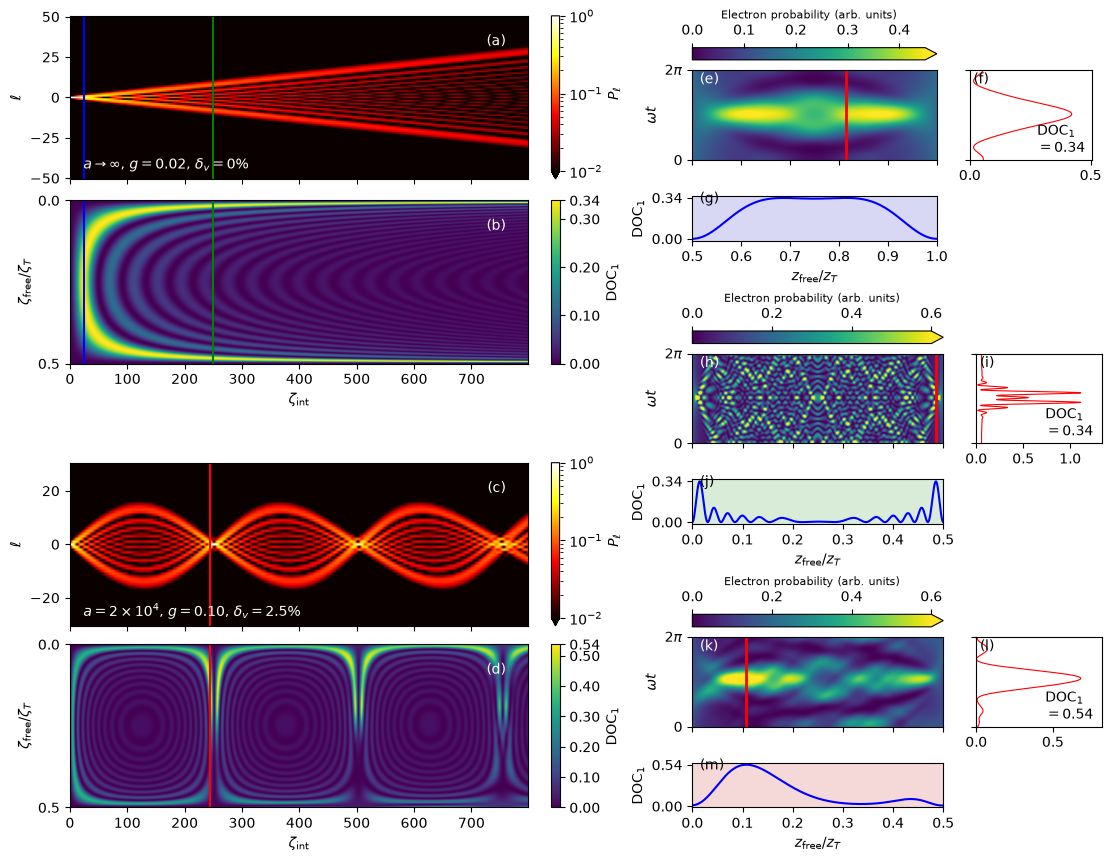

In [4]:
hot = plt.get_cmap("hot").copy(); hot.set_under(hot(0.0)); hot.set_bad(hot(0.0))
fig = plt.figure(figsize=(11, 8.5), constrained_layout=True)
outer = fig.add_gridspec(1, 2, width_ratios=[1.3, 1])

left = outer[0].subgridspec(5, 1, height_ratios=[1, 1, 0.25, 1, 1])
rows = [("nonrecoil", "a", "b", [(25, "b"), (250, "g")], r"$a\to\infty$, $g=0.02$, $\delta_v=0\%$"),
        ("recoil", "c", "d", [(244, "r")], r"$a=2\times10^4$, $g=0.10$, $\delta_v=2.5\%$")]
for r, (key, la, lb, lines, txt) in enumerate(rows):
    ax1 = fig.add_subplot(left[3 * r]); ax2 = fig.add_subplot(left[3 * r + 1], sharex=ax1)
    zeta, ell, P = pr.load_map(files_map[key][0])
    _, s_free, D = pr.load_map(files_map[key][1])      # D[i_s, i_zeta]
    im1 = ax1.imshow(P, origin="lower", aspect="auto", cmap=hot, norm=LogNorm(1e-2, 1),
                     extent=[zeta[0] - 0.5, zeta[-1] + 0.5, ell[0] - 0.5, ell[-1] + 0.5])
    ax1.set_ylabel(r"$\ell$"); ax1.tick_params(labelbottom=False)
    ax1.text(0.03, 0.06, txt, color="w", transform=ax1.transAxes)
    fig.colorbar(im1, ax=ax1, extend="min").set_label(r"$P_\ell$")
    im2 = ax2.imshow(D, origin="upper", aspect="auto", cmap="viridis",
                     extent=[zeta[0] - 0.5, zeta[-1] + 0.5, s_free[-1], s_free[0]])
    ax2.set_yticks([0, 0.5]); ax2.set_ylabel(r"$\zeta_{\rm free}/\zeta_T$"); ax2.set_xlabel(r"$\zeta_{\rm int}$")
    cb = fig.colorbar(im2, ax=ax2); cb.set_label(r"DOC$_1$")
    cb.set_ticks([0, 0.1, 0.2, 0.3, 0.4, 0.5][: int(D.max() / 0.1) + 1] + [D.max()])
    cb.ax.yaxis.set_major_formatter("{x:.2f}")
    for x, col in lines:
        ax1.axvline(x, color=col, lw=1.5); ax2.axvline(x, color=col, lw=1.5)
    ax1.text(0.95, 0.82, f"({la})", color="w", transform=ax1.transAxes, ha="right")
    ax2.text(0.95, 0.82, f"({lb})", color="w", transform=ax2.transAxes, ha="right")

right = outer[1].subgridspec(3, 1)
for r, (name, letters, bg) in enumerate([("efg", "efg", "#d8d8f5"), ("hij", "hij", "#d8ecd8"), ("klm", "klm", "#f5d8d8")]):
    s, th, dens = pr.load_map(files_pulse[name]["density"])
    doc = pr.load_columns(files_pulse[name]["DOC1"])["DOC1"]
    sub = right[r].subgridspec(2, 2, width_ratios=[2, 1], height_ratios=[2, 1])
    ax_e = fig.add_subplot(sub[0, 0]); ax_f = fig.add_subplot(sub[0, 1], sharey=ax_e)
    ax_g = fig.add_subplot(sub[1, 0], sharex=ax_e)
    i_max = np.argmax(doc)
    im = ax_e.imshow(dens, origin="lower", aspect="auto", cmap="viridis", vmin=0, vmax=pulses[name]["vmax"],
                     extent=[s[0], s[-1], th[0], th[-1]])
    ax_e.axvline(s[i_max], color="r", lw=2)
    ax_e.set_yticks([0, 2 * np.pi], ["0", r"$2\pi$"]); ax_e.set_ylabel(r"$\omega t$"); ax_e.tick_params(labelbottom=False)
    fig.colorbar(im, ax=ax_e, location="top", extend="max").set_label("Electron probability (arb. units)", fontsize=8)
    ax_f.plot(dens[:, i_max], th, "r-", lw=0.8)
    ax_f.set_xlim(0, 1.2 * dens[:, i_max].max()); ax_f.tick_params(labelleft=False)
    ax_f.text(0.55, 0.08, r"DOC$_1$" + "\n" + rf"$={doc[i_max]:.2f}$", transform=ax_f.transAxes)
    ax_g.plot(s, doc, "b-")
    ax_g.set_yticks([0, round(doc.max(), 2)]); ax_g.set_ylabel(r"DOC$_1$")
    ax_g.set_xlabel(r"$z_{\rm free}/z_T$")
    for ax, lab, col in zip([ax_e, ax_f, ax_g], letters, ["w", "k", "k"]):
        ax.text(0.03, 0.85, f"({lab})", color=col, transform=ax.transAxes)
        ax.set_facecolor(bg) if ax is ax_g else None
fig.savefig(FIGS / "fig8.png", dpi=200)
fig.savefig(FIGS / "fig8.pdf")
plt.show()